# **Chapter 18**


- Graph are abstract data strucures. 
- Garaphs have certain properties. 

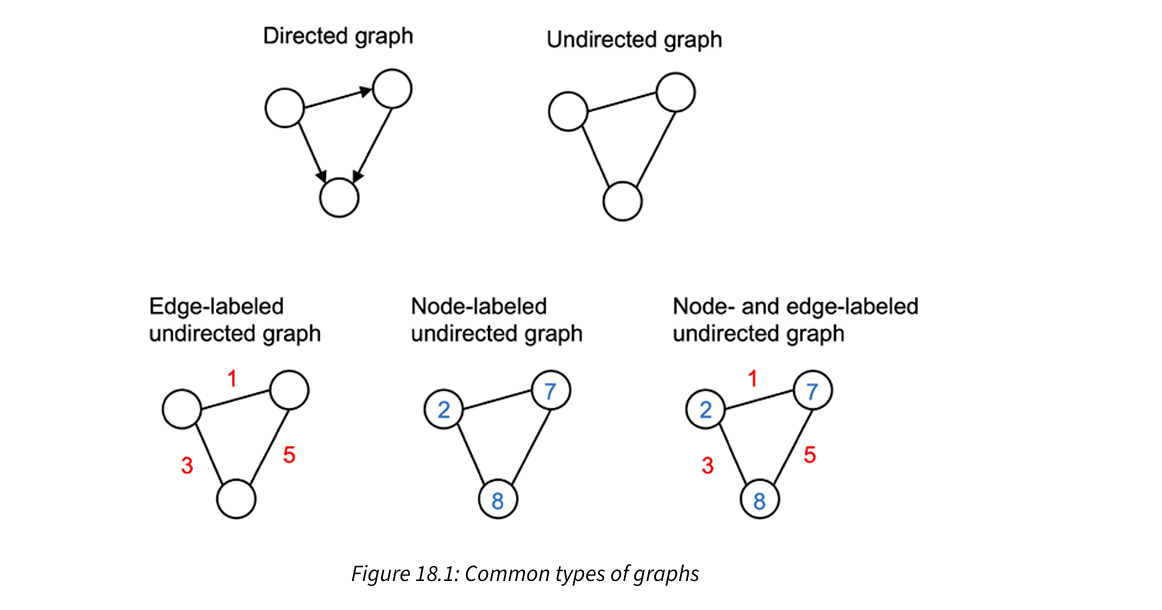

- Undirected graphas G with pair (V,E). V the nodes and E the edges. |V| * |V| gives us a mtrix A. where x_i_j is the edgeg connecting node i and nodej. each x_i_j = 1 if connected and zero oherwise. note: x_i_j = x_j_i 

- Directed graphs same as undirected graphs but E in this case is are ordered pairs. hence x_i_j != x_j_i 

- Labaled graphs : in this case the nodes and edges have features to them. |V| * f_v  and |E| * f_e 

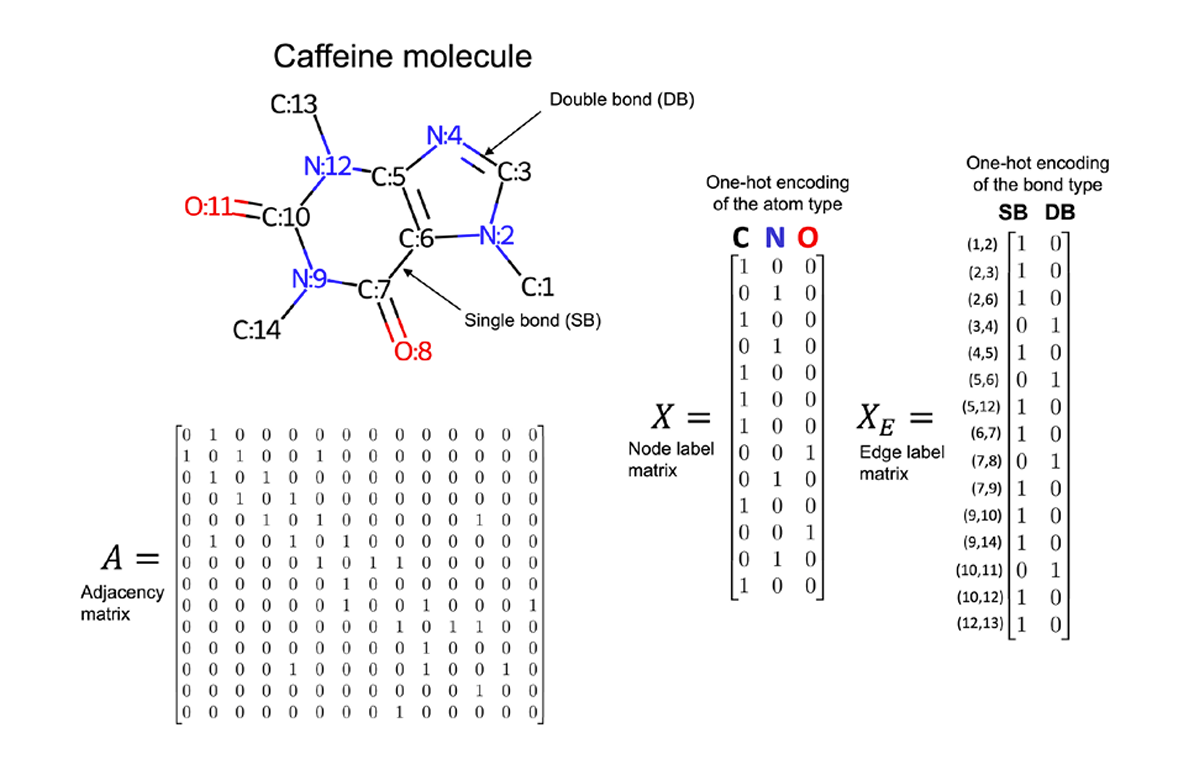

### Motivation behing graph convolutions 

- Convultion is the process of slidding a filter over an image at each step weighed sum is calculated at each step btween the fielder and receptive field in the case of image. 
- Convultion is  a detector ofor specifc features. it is well suited for images. 
      - shift invariance : a feature in an image can be recognaied regacrless location 
      - Locality : nearby pixels are simialr 
      - Hierachy: higher features can be broken into smaller parts. 
      - Number of trainable parammerters are not depeent on the size of the image 

- In the case of grpahs , The locality prior is shared. In this case we define locality as strucutral locality i.e a node that is 1 edge away is more likely to be related to a node 5 edges away. Permutation invariance --> the ordering of the nodes does not change the gepahs structure.Moreovr , The paramters are fixed.  

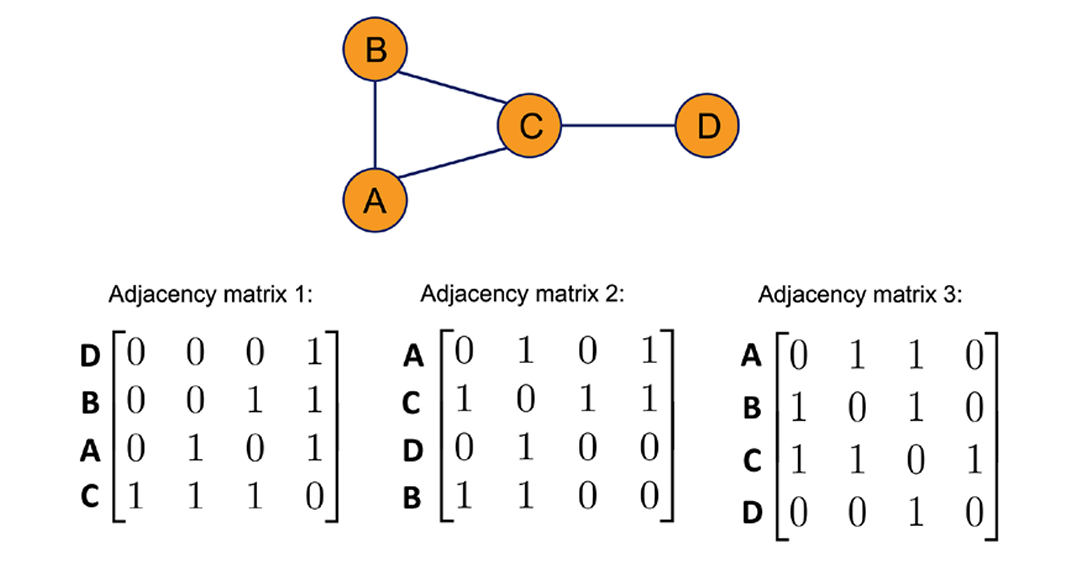

### Implementing graphs convolution 

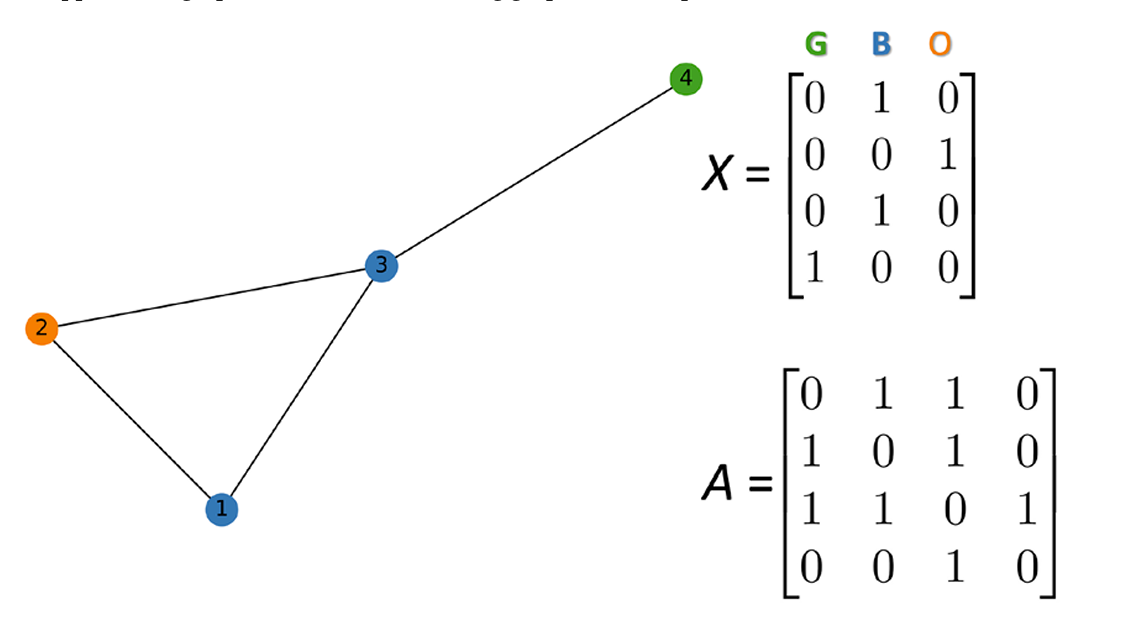

In [1]:
!pip install networkx

In [2]:
import  networkx as nx
import numpy as np

In [3]:
G = nx.Graph()  # define the graph 

blue, orange, green = "#1f77b4", "#ff7f0e", "#2ca02c"
G.add_nodes_from([(1,{"color": blue}),
                  (2,{"color": orange}),
                  (3,{"color": green}),
                  (4,{"color": orange})])  # add nodes to the graph

G.add_edges_from([(1,2) , (2,3) , (3,1) , (3,4)])  # add edges to the graph
A = np.asarray(nx.adjacency_matrix(G).todense())
print(A)

[[0 1 1 0]
 [1 0 1 0]
 [1 1 0 1]
 [0 0 1 0]]


In [ ]:
def build_graph_color_label_representation(G , mapping_dict): 
    one_hot_idxs = np.array([mapping_dict[v] for v in nx.get_node_attributes(G , "color").values()])
    one_hot_encoding = np.zeros((one_hot_idxs.size, len(mapping_dict)))
    one_hot_encoding[np.arange(one_hot_idxs.size), one_hot_idxs] = 1
    return one_hot_encoding

X = build_graph_color_label_representation(G , {blue:0 , orange:1 , green:2})

print(X)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]


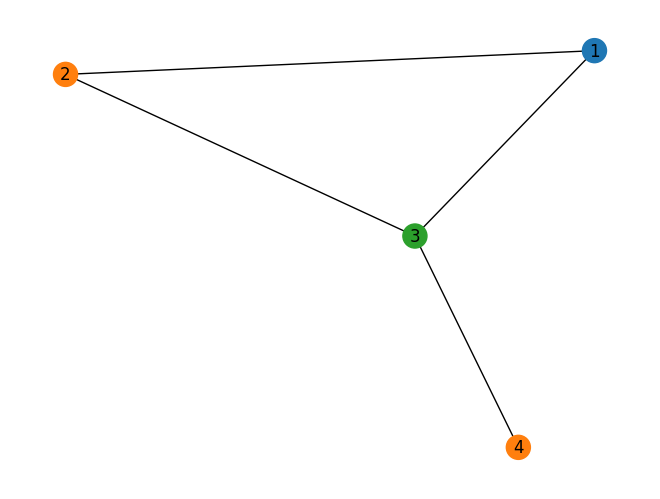

In [5]:
color_map = list(nx.get_node_attributes(G , "color").values())
nx.draw(G , with_labels=True , node_color=color_map)

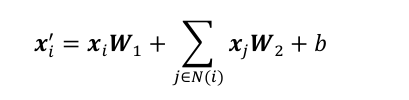

Note:  Note that this filter design is most effective when the locality prior on graph data holds. stacking multiple graph convoultuons will capture more distant infromation. 

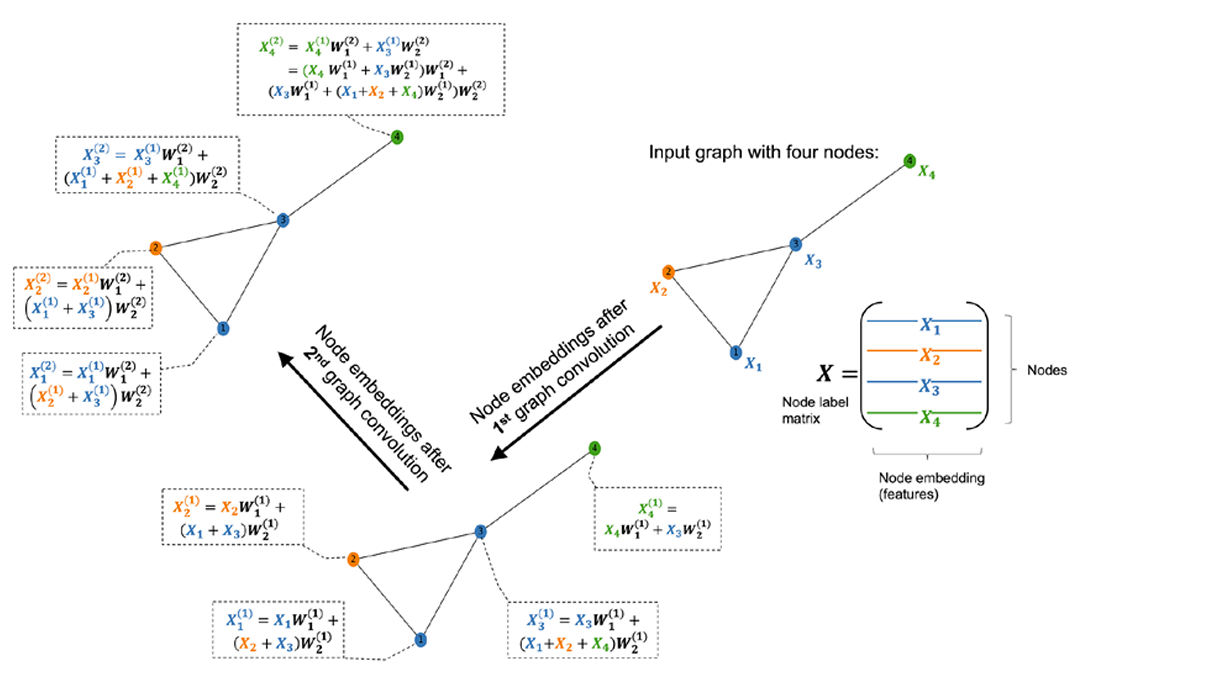

### Message Passing 

-  each node in the graph has an associated hidden state ℎ𝑖𝑖
(𝑡𝑡) , where 
i is the node’s index at time step t. The initial value ℎ𝑖𝑖
(0)  is defined as Xi, which is the row of X associated 
with node i.
- . Let N(i) 
be the neighbors of node i. For undirected graphs, N(i) is the set of nodes that share an edge with 
node i.
- 

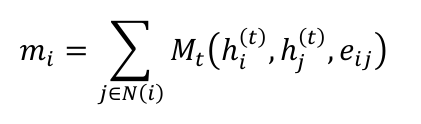

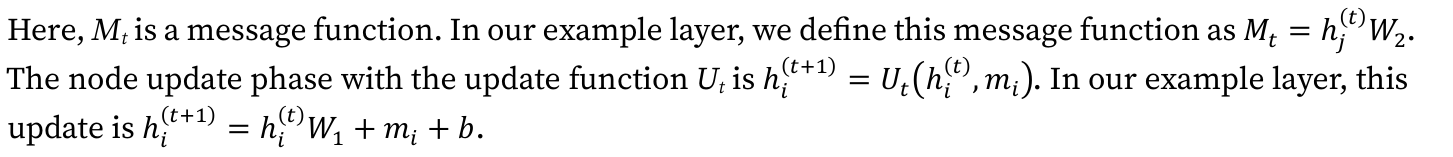

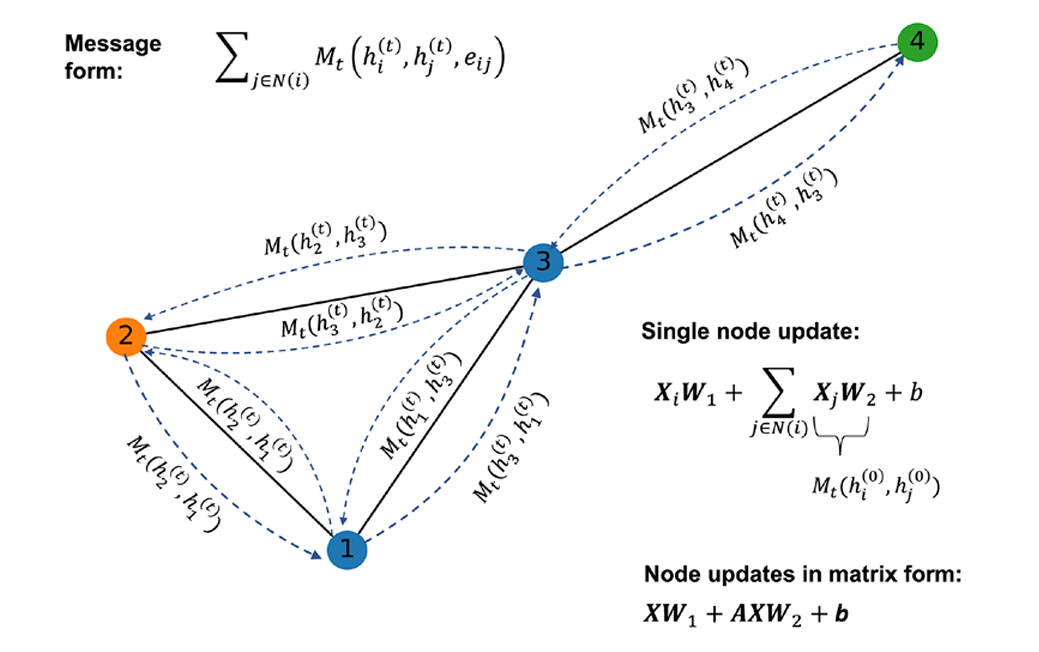

## Implementing a GNN in PyTorch from scratch


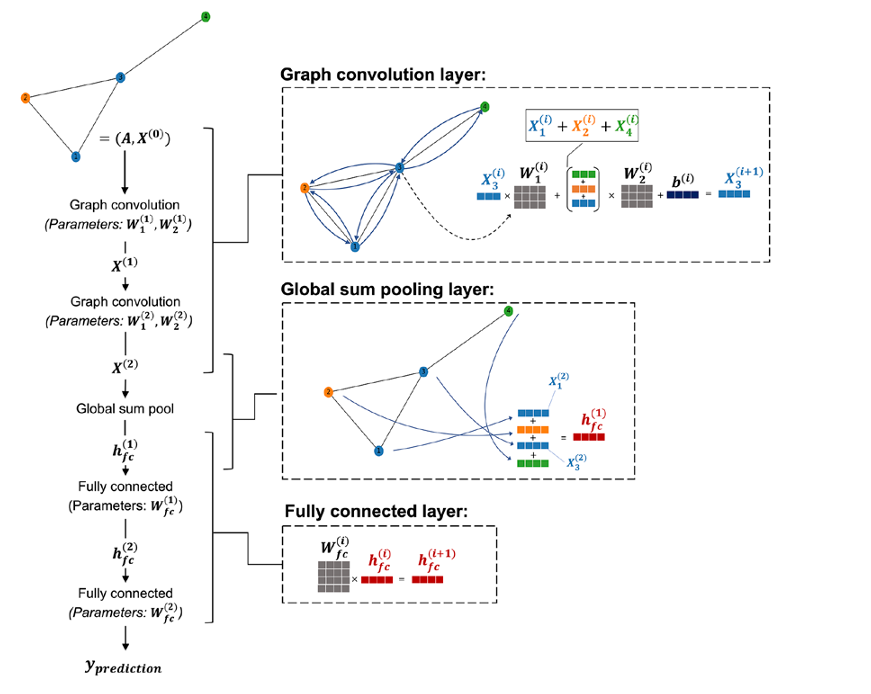

In [6]:
import networkx as nx
import torch 
from  torch.nn.parameter import Parameter 
import math 
import torch.nn.functional as F

In [ ]:
class BasicGraphConvolutionLayer(torch.nn.Module): 
    def __init__(self , in_channels , our_channels): 
        super().__init__()
        self.in_channels = in_channels
        self.our_channels = our_channels
        self.W2 = Parameter(torch.rand((in_channels , our_channels) , dtype=torch.float32 )) 
        self.W1 = Parameter(torch.rand((in_channels , our_channels) , dtype=torch.float32 ))
        self.bias = Parameter(torch.zeros((our_channels ,) , dtype=torch.float32))

    def forward(self , X , A ): 
        potential_msgs = torch.mm(X , self.W2)
        propagates_msgs = torch.mm(A , potential_msgs)
        root_update = torch.mm(X , self.W1)
        output = propagates_msgs + root_update + self.bias 
        return output

In [8]:
print('X.shape:', X.shape) 
print('A.shape:', A.shape) 
basiclayer = BasicGraphConvolutionLayer(3, 8)
out = basiclayer(X=torch.tensor(X, dtype=torch.float32), A=torch.tensor(A, dtype=torch.float32))
print('Output shape:', out.shape)

X.shape: (4, 3)
A.shape: (4, 4)
Output shape: torch.Size([4, 8])


BasicGraphConvolutionLayer converted the 
four-node graph consisting of three features into a representation with eight features.

the better way to deal with varying graph sizes is to treat each batch 
as a single graph where each graph in the batch is a subgraph that is disconnected from the rest. 


In [ ]:
def global_sum_pool(X , batch_mat): 
    if batch_mat is None or batch_mat.dim() == 1 : 
        return torch.sum(X , dim=0 , keepdim=True)
    else : 
        return torch.mm(batch_mat , X )

In [ ]:


class NodeNetwork(torch.nn.Module): 
    def __init__(self , input_features): 
        super().__init__()
        self.conv_1 = BasicGraphConvolutionLayer(input_features , 32)
        self.conv_2 = BasicGraphConvolutionLayer(32 , 32)
        self.fc_1 = torch.nn.Linear(32 , 16)
        self.out_layer = torch.nn.Linear(16 , 2)

    def forward(self , X , A , batch_mat): 
        X = F.relu(self.conv_1(X, A))
        X = F.relu(self.conv_2(X, A))
        output = global_sum_pool(X , batch_mat)
        output = self.fc_1(output)
        output = self.out_layer(output)
        return F.softmax(output , dim=1)

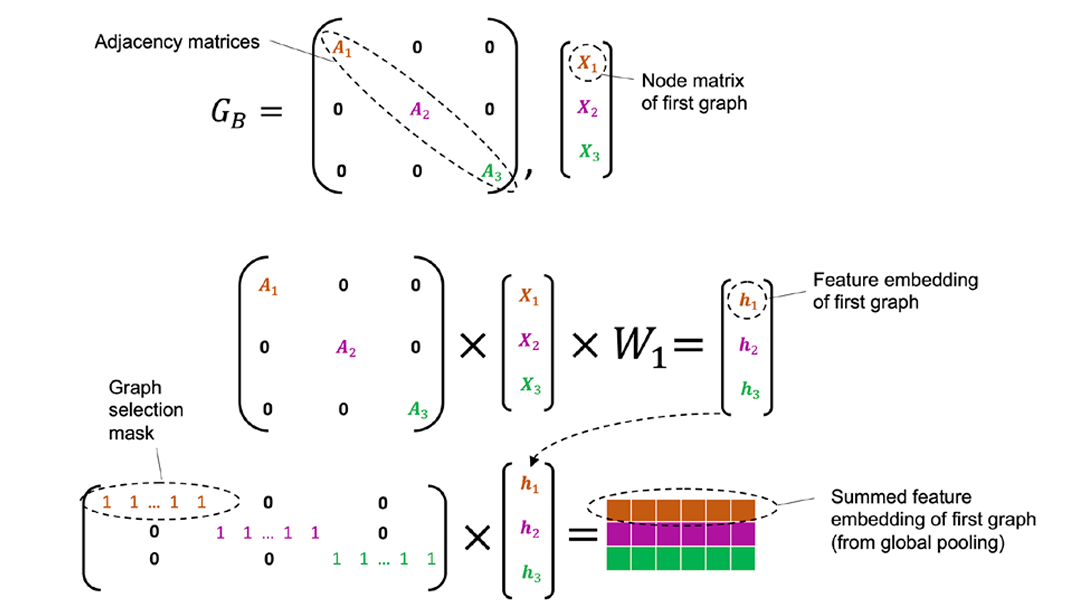

In [11]:
def get_batch_tensor(graph_sizes):
    starts = [sum(graph_sizes[:idx]) for idx in range(len(graph_sizes))]
    stops = [starts[idx] + graph_sizes[idx] for idx in range(len(graph_sizes))]

    tot_len = sum(graph_sizes)
    batch_size = len(graph_sizes)
    batch_mat = torch.zeros([batch_size, tot_len]).float()
    for idx , starts_and_stops in enumerate(zip(starts, stops)):
        start = starts_and_stops[0]
        stop = starts_and_stops[1]
        batch_mat[idx, start:stop] = 1.0
    return batch_mat

In [ ]:
def collate_graph(batch): 
    adj_mats = [graph["A"] for graph in batch]
    sizes = [A.size(0) for A in adj_mats]
    total_size = sum(sizes)
    batch_mat = get_batch_tensor(sizes)
    feat_mats = torch.cat([graph["X"] for graph in batch], dim=0)
    labels = torch.cat([graph["y"] for graph in batch], dim=0)
    batch_adj = torch.zeros((total_size, total_size)).float()
    accum = 0 
    for adj in adj_mats : 
        g_size = adj.shape[0]
        batch_adj[accum:accum + g_size, accum:accum + g_size] = adj
        accum += g_size
    repr_and_label = {"X": feat_mats, "A": batch_adj, "y": labels, "batch": batch_mat}
    return repr_and_label

In [13]:
def get_graph_dict(G , mapping_dict): 
    A = torch.from_numpy(np.asarray(nx.adjacency_matrix(G).todense())).float()
    X = torch.from_numpy(build_graph_color_label_representation(G , mapping_dict)).float()
    y = torch.tensor([[1,0]]).float()
    return {"X": X , "A": A , "y": y , "batch" : None }


In [ ]:
blue, orange, green = "#1f77b4", "#ff7f0e","#2ca02c"
mapping_dict= {green:0, blue:1, orange:2}

G1 = nx.Graph()
G1.add_nodes_from([
    (1,{"color": blue}),
    (2,{"color": orange}),
    (3,{"color": blue}),
    (4,{"color": green})
])
G1.add_edges_from([(1, 2), (2, 3), (1, 3), (3, 4)])

G2 = nx.Graph()
G2.add_nodes_from([
    (1,{"color": green}),
    (2,{"color": green}),
    (3,{"color": orange}),
    (4,{"color": orange}),
    (5,{"color": blue})
])
G2.add_edges_from([(2, 3),(3, 4),(3, 1),(5, 1)])

G3 = nx.Graph()
G3.add_nodes_from([
    (1,{"color": orange}),
    (2,{"color": orange}),
    (3,{"color": green}),
    (4,{"color": green}),
    (5,{"color": blue}),
    (6,{"color":orange})
])
G3.add_edges_from([(2,3), (3,4), (3,1), (5,1), (2,5), (6,1)])

G4 = nx.Graph()
G4.add_nodes_from([
    (1,{"color": blue}),
    (2,{"color": blue}),
    (3,{"color": green})
])
G4.add_edges_from([(1, 2), (2, 3)])

graph_list = [get_graph_dict(graph, mapping_dict) for graph in
    [G1, G2, G3, G4]]

In [ ]:
from torch.utils.data import Dataset 
class ExampleDataset(Dataset): 

    def __init__(self , graph_list): 
        self.graph_list = graph_list

    def __len__(self): 
        return len(self.graph_list)

    def __getitem__(self , idx): 
        return self.graph_list[idx]

In [ ]:
from torch.utils.data import DataLoader
dset = ExampleDataset(graph_list)
loader = DataLoader(dset , batch_size=2 , collate_fn=collate_graph)

node_features = 3  
net = NodeNetwork(node_features)
batch_results = []
for b in loader: 
    batch_results.append(net(b["X"], b["A"], b["batch"]).detach())
G1_rep = dset[1]
G1_single = net(G1_rep["X"] , G1_rep["A"] , G1_rep["batch"])
G1_batch = batch_results[0][1]
torch.all(torch.isclose(G1_single , G1_batch))


tensor(True)

### Pytorch Geometric 

In [18]:
!pip install torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 26.8 MB/s eta 0:00:00a 0:00:01


In [19]:
import torch
from torch_geometric.datasets import QM9
from torch_geometric.loader import DataLoader
from torch_geometric.nn import NNConv, global_add_pool
import torch.nn.functional as F
import torch.nn as nn
import numpy as np

In [20]:
dset = QM9(".")
len(dset)

Extracting ./raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


130831

In [21]:
data = dset[0]
data 

Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5])

In [22]:
data.z

tensor([6, 1, 1, 1, 1])

In [23]:
data.new_attribute = torch.tensor([1,2,3])
data 

Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5], new_attribute=[3])

In [24]:
device = torch.device(
"cuda:0" if torch.cuda.is_available() else "cpu")
data.to(device)
data.new_attribute.is_cuda

True

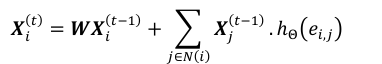

In [30]:
class ExampleNet(torch.nn.Module): 
    def __init__(self , num_node_features , num_edge_features): 
        super().__init__()
        conv1_net = nn.Sequential(
            nn.Linear(num_edge_features, 32), 
            nn.ReLU(), 
            nn.Linear(32, num_node_features * 32)
        )
        conv2_net = nn.Sequential(
            nn.Linear(num_edge_features, 32), 
            nn.ReLU(), 
            nn.Linear(32, 32*16)
        )

        self.conv1 = NNConv(num_node_features , 32 , conv1_net)
        self.conv2 = NNConv(32 , 16 , conv2_net)
        self.fc_1 = nn.Linear(16,32)
        self.out  = nn.Linear(32 , 1 )

    def forward(self , data): 
        batch , x , edge_index , edge_attr = (data.batch , data.x , data.edge_index , data.edge_attr)
        x = F.relu(self.conv1(x , edge_index , edge_attr))
        x = F.relu(self.conv2(x , edge_index , edge_attr))
        x = global_add_pool(x , batch)
        x = F.relu(self.fc_1(x))
        x = self.out(x)
        return x
    

In [33]:
from torch.utils.data import random_split
train_set, valid_set, test_set = random_split(
     dset,[110000, 10831, 10000])
trainloader = DataLoader(train_set, batch_size=32, shuffle=True)
validloader = DataLoader(valid_set, batch_size=32, shuffle=True)
testloader = DataLoader(test_set, batch_size=32, shuffle=True)

In [34]:
qm9_node_feats, qm9_edge_feats = 11, 4
net = ExampleNet(qm9_node_feats, qm9_edge_feats)
# initialize an optimizer with some reasonable parameters
optimizer = torch.optim.Adam(
     net.parameters(), lr=0.01)
epochs = 4
target_idx = 1 # index position of the polarizability label
device = torch.device("cuda:0" if
                       torch.cuda.is_available() else "cpu")
net.to(device)

ExampleNet(
  (conv1): NNConv(11, 32, aggr=add, nn=Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=352, bias=True)
  ))
  (conv2): NNConv(32, 16, aggr=add, nn=Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=512, bias=True)
  ))
  (fc_1): Linear(in_features=16, out_features=32, bias=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)

In [36]:
for total_epochs in range(epochs):
     epoch_loss = 0        
     total_graphs = 0
     net.train()
     for batch in trainloader:
                    batch.to(device)
                    optimizer.zero_grad()
                    output = net(batch)
                    loss = F.mse_loss(
                        output,batch.y[:, target_idx].unsqueeze(1))
                    loss.backward()
                    epoch_loss += loss.item()
                    total_graphs += batch.num_graphs
                    optimizer.step()
                    
     train_avg_loss = epoch_loss / total_graphs
     val_loss = 0
     total_graphs = 0
     net.eval()
     for batch in validloader:
                batch.to(device)
                output = net(batch)
                loss = F.mse_loss(
                    output,batch.y[:, target_idx].unsqueeze(1))
                val_loss += loss.item()
                total_graphs += batch.num_graphs
     val_avg_loss = val_loss / total_graphs
     print(f"Epochs: {total_epochs} | "
        f"epoch avg. loss: {train_avg_loss:.2f} | "
        f"validation avg. loss: {val_avg_loss:.2f}")

Epochs: 0 | epoch avg. loss: 0.11 | validation avg. loss: 0.08
Epochs: 1 | epoch avg. loss: 0.09 | validation avg. loss: 0.08
Epochs: 2 | epoch avg. loss: 0.08 | validation avg. loss: 0.08
Epochs: 3 | epoch avg. loss: 0.08 | validation avg. loss: 0.05


In [37]:
net.eval()
predictions = []
real = []
for batch in testloader:
    output = net(batch.to(device))
    predictions.append(output.detach().cpu())
    real.append(batch.y[:, target_idx].unsqueeze(1).detach().cpu())
real = torch.cat(real, dim=0)
predictions = torch.cat(predictions, dim=0)

Text(0, 0.5, 'Predicted isotropic polarizability')

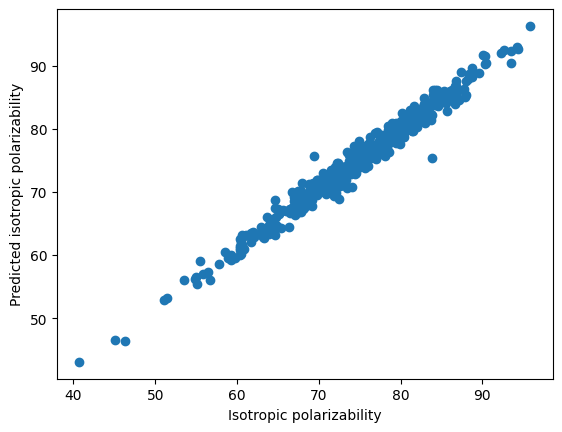

In [38]:
import matplotlib.pyplot as plt
plt.scatter(real[:500], predictions[:500])
plt.xlabel('Isotropic polarizability')
plt.ylabel('Predicted isotropic polarizability')